# More Thinking, Less Reading?
## The Cost and Boundary Conditions of Reasoning Mode for Factual QA

### Research question
**Does enabling reasoning mode improve factual recall enough to justify its token cost, and does it weaken adherence to explicit textual evidence?**

This notebook implements a **same-model causal comparison** using Qwen3's official hard switch:
- `enable_thinking=False`
- `enable_thinking=True`

The model weights, question, context, and decoding hyperparameters are held fixed; only reasoning mode changes.

### Design
1. Draw an untouched 150-fact PopQA subset and compare Think versus NoThink across three matched decoding seeds.
2. Report paired fact-level inference and token cost; this independent subset is the headline evaluation.
3. Separately screen facts the model knows and create boundary controls:
   - **aligned context**: supplied value agrees with the known fact;
   - **conflict context**: supplied value is replaced by another object from the same relation.
4. Run the same model with thinking OFF and ON.
5. Classify the final answer automatically as **context**, **prior**, or **other**.
6. Test whether explicit records prevent any recall degradation or grounding drift.

### Simple contributions
1. **Independent paired evidence:** on untouched PopQA facts, reasoning mode provides no reliable factual-accuracy gain and is directionally worse.
2. **Compute cost:** thinking uses roughly 39× more generated tokens per answer.
3. **Boundary condition:** explicit aligned or conflicting records yield 100% adherence in both modes, so the observed inefficiency is not evidence of weaker textual grounding.

### Primary metrics
\[
CAA=P(\text{follow supplied context})
\]

\[
PRR=P(\text{return original parametric prior})
\]

\[
RGD=PRR_{Think}-PRR_{NoThink}
\]

\[
GFR=P(NoThink=Context,\ Think=Prior)
\]

Positive RGD means thinking causes more prior reversion.

### Primary sources
- Qwen3 official model card: https://huggingface.co/Qwen/Qwen3-4B
- Qwen3 official blog: https://qwenlm.github.io/blog/qwen3/
- PopQA: https://huggingface.co/datasets/akariasai/PopQA

In [1]:
%pip install -q -U transformers==5.15.0 accelerate==1.14.0 bitsandbytes==0.50.0 datasets pandas numpy scipy matplotlib tqdm


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Configuration

Start with `smoke=True`. For a paper run set `smoke=False`.

Qwen's official model card recommends sampling rather than greedy decoding in thinking mode. To avoid a decoding-policy confound, this notebook uses the **same sampling settings in both modes**.

In [2]:
from dataclasses import dataclass
from pathlib import Path
import ast
import gc
import json
import random
import re

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset
from scipy.stats import binomtest
from tqdm.auto import tqdm
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
    LogitsProcessor,
)


@dataclass
class Config:
    model_id: str = "Qwen/Qwen3-4B"
    output_dir: str = "./grounding_drift_results"

    smoke: bool = False
    candidate_pool_smoke: int = 60
    # Qwen3-4B-4bit recalled about 8% of an initial 500-item screen.
    # A 2,500-item pool provides margin for the fixed 150-example target.
    candidate_pool_full: int = 2500
    target_examples_smoke: int = 20
    target_examples_full: int = 150

    # The shared A10 cannot hold the 4B checkpoint in BF16 beside other jobs.
    # Single-GPU 4-bit loading avoids fragile automatic cross-GPU sharding.
    use_4bit: bool = True
    temperature: float = 0.6
    top_p: float = 0.95
    top_k: int = 20
    max_new_tokens_direct: int = 64
    max_new_tokens_think: int = 256

    decode_seeds_smoke: tuple = (17,)
    decode_seeds_full: tuple = (17, 29, 41)

    eval_seed: int = 20260811
    bootstrap_samples: int = 5000


CFG = Config()
OUT = Path(CFG.output_dir)
OUT.mkdir(parents=True, exist_ok=True)

CANDIDATE_POOL = CFG.candidate_pool_smoke if CFG.smoke else CFG.candidate_pool_full
TARGET_EXAMPLES = CFG.target_examples_smoke if CFG.smoke else CFG.target_examples_full
DECODE_SEEDS = CFG.decode_seeds_smoke if CFG.smoke else CFG.decode_seeds_full

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = (
    torch.bfloat16
    if torch.cuda.is_available() and torch.cuda.is_bf16_supported()
    else (torch.float16 if torch.cuda.is_available() else torch.float32)
)

print("device:", DEVICE)
print("dtype:", DTYPE)
print("smoke:", CFG.smoke)
print("candidate pool:", CANDIDATE_POOL)
print("target examples:", TARGET_EXAMPLES)
print("decode seeds:", DECODE_SEEDS)

/home/security/Azka_container/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda
dtype: torch.bfloat16
smoke: False
candidate pool: 2500
target examples: 150
decode seeds: (17, 29, 41)


## 2. Load and clean PopQA

To reduce ambiguity, we keep only `(subject, relation)` pairs appearing once in PopQA and only relations with at least two distinct objects.

In [3]:
raw = load_dataset("akariasai/PopQA", split="test")
df = raw.to_pandas().copy()

def parse_possible_answers(value):
    if isinstance(value, list):
        return [str(x) for x in value]
    if isinstance(value, np.ndarray):
        return [str(x) for x in value.tolist()]
    if value is None:
        return []
    if isinstance(value, str):
        s = value.strip()
        try:
            parsed = ast.literal_eval(s)
            if isinstance(parsed, (list, tuple)):
                return [str(x) for x in parsed]
        except Exception:
            pass
        return [s]
    return [str(value)]

df["gold_aliases"] = df["possible_answers"].apply(parse_possible_answers)
df["gold_aliases"] = df.apply(
    lambda r: list(dict.fromkeys([str(r["obj"])] + r["gold_aliases"])),
    axis=1,
)

pair_counts = df.groupby(["subj", "prop"]).size()
unique_pairs = pair_counts[pair_counts == 1].index
mask = pd.MultiIndex.from_frame(df[["subj", "prop"]]).isin(unique_pairs)
df = df.loc[mask].reset_index(drop=True)

rel_obj_counts = df.groupby("prop")["obj"].nunique()
valid_props = rel_obj_counts[rel_obj_counts >= 2].index
df = df[df["prop"].isin(valid_props)].reset_index(drop=True)

print("usable rows:", len(df))
display(df["prop"].value_counts().to_frame("count"))

Repo card metadata block was not found. Setting CardData to empty.


usable rows: 12184


,count
prop,
director,1627
genre,1453
screenwriter,1446
author,1321
producer,1157
country,811
composer,805
capital,606
place of birth,584


## 3. Load Qwen3

The key control is that both conditions use **the same model weights**.

In [4]:
def load_model_and_tokenizer(cfg=CFG):
    tokenizer = AutoTokenizer.from_pretrained(cfg.model_id, use_fast=True)
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "left"

    kwargs = {"dtype": DTYPE, "attn_implementation": "eager"}
    if cfg.use_4bit:
        if not torch.cuda.is_available():
            raise RuntimeError("4-bit Qwen3 loading requires CUDA.")
        kwargs["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=DTYPE,
            bnb_4bit_use_double_quant=True,
        )
        kwargs["device_map"] = {"": 0}
    elif torch.cuda.is_available():
        kwargs["device_map"] = {"": 0}

    model = AutoModelForCausalLM.from_pretrained(cfg.model_id, **kwargs)
    model.eval()
    return model, tokenizer

model, tokenizer = load_model_and_tokenizer()
print("loaded:", CFG.model_id)

Loading weights: 100%|██████████| 398/398 [00:01<00:00, 229.99it/s]


loaded: Qwen/Qwen3-4B


## 4. Prompt templates

Counterfactual contexts are explicitly labeled **fictional records**, so we are not presenting false facts as real-world claims.

In [5]:
def record_prompt(row, record_value):
    return (
        "Use ONLY the fictional record below as the source of truth for this task.\n"
        "Even if it conflicts with your real-world knowledge, answer according to the record.\n\n"
        "Fictional record:\n"
        f"Subject: {row['subj']}\n"
        f"Relation: {row['prop']}\n"
        f"Value: {record_value}\n\n"
        f"Question: {row['question']}\n\n"
        "Return only the answer value. Do not explain your answer."
    )

def no_context_prompt(row):
    return (
        "Answer the factual question below using your knowledge.\n"
        "Return only the answer value. Do not explain your answer.\n\n"
        f"Question: {row['question']}"
    )

## 5. Generation helper

We decode the final answer **after `</think>`**. Thinking mode receives a larger token budget because reasoning tokens consume generation budget.

In [6]:
def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def split_qwen_thinking(output_ids, tokenizer):
    ids = output_ids.tolist() if hasattr(output_ids, "tolist") else list(output_ids)
    end_think_id = tokenizer.convert_tokens_to_ids("</think>")

    valid_end_id = (
        end_think_id is not None
        and end_think_id != tokenizer.unk_token_id
        and end_think_id in ids
    )

    if valid_end_id:
        rev_idx = ids[::-1].index(end_think_id)
        idx = len(ids) - 1 - rev_idx
        thinking_ids = ids[: idx + 1]
        final_ids = ids[idx + 1 :]
    else:
        thinking_ids = []
        final_ids = ids

    thinking = tokenizer.decode(thinking_ids, skip_special_tokens=True).strip()
    final = tokenizer.decode(final_ids, skip_special_tokens=True).strip()
    return thinking, final

class FiniteLogitsProcessor(LogitsProcessor):
    # Fail synchronously with a useful message instead of poisoning CUDA in
    # torch.multinomial if a backend ever emits NaN/Inf token scores.
    def __call__(self, input_ids, scores):
        if not torch.isfinite(scores).all():
            raise FloatingPointError("Model produced non-finite generation logits.")
        return scores


@torch.inference_mode()
def generate_answer(
    prompt, enable_thinking, seed, sample=True,
    model=model, tokenizer=tokenizer, cfg=CFG,
):
    set_all_seeds(seed)

    messages = [{"role": "user", "content": prompt}]
    rendered = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=enable_thinking,
    )

    batch = tokenizer(rendered, return_tensors="pt")
    batch = {k: v.to(model.device) for k, v in batch.items()}

    max_new = cfg.max_new_tokens_think if enable_thinking else cfg.max_new_tokens_direct

    generation_kwargs = {
        "do_sample": sample,
        "max_new_tokens": max_new,
        "pad_token_id": tokenizer.pad_token_id,
        "eos_token_id": tokenizer.eos_token_id,
        "logits_processor": [FiniteLogitsProcessor()],
        "renormalize_logits": True,
    }
    if sample:
        generation_kwargs.update({
            "temperature": cfg.temperature,
            "top_p": cfg.top_p,
            "top_k": cfg.top_k,
        })

    generated = model.generate(**batch, **generation_kwargs)

    new_ids = generated[0, batch["input_ids"].shape[1]:]
    thinking, final = split_qwen_thinking(new_ids, tokenizer)

    return {
        "thinking": thinking,
        "final": final,
        "generated_tokens": int(len(new_ids)),
        "thinking_chars": len(thinking),
    }

## 6. Automatic answer normalization and classification

In [7]:
ARTICLES = {"a", "an", "the"}

def normalize_answer(text):
    if text is None:
        return ""
    text = str(text).strip().lower()
    # Thinking-mode generations can legitimately end without a final answer
    # inside the token budget. Treat empty output as unmatched, not an error.
    if not text:
        return ""
    text = text.splitlines()[0].strip()
    text = re.sub(r"^(final answer|answer|value)\s*:\s*", "", text)
    text = re.sub(r"^(the answer is|it is)\s+", "", text)
    text = "".join(ch if ch.isalnum() or ch.isspace() else " " for ch in text)
    toks = [t for t in text.split() if t not in ARTICLES]
    return " ".join(toks).strip()

def alias_set(values):
    return {normalize_answer(v) for v in values if normalize_answer(v)}

def classify_conflict(final_text, context_value, prior_aliases):
    pred = normalize_answer(final_text)
    context_norm = normalize_answer(context_value)
    priors = alias_set(prior_aliases)

    if pred == context_norm:
        return "context"
    if pred in priors:
        return "prior"
    return "other"

def matches_gold(final_text, aliases):
    return normalize_answer(final_text) in alias_set(aliases)

assert normalize_answer("Answer: Paris.") == "paris"
assert matches_gold("The answer is Paris", ["Paris"])
assert normalize_answer("") == ""
print("normalization tests passed")

normalization tests passed


## 7. Screen for facts the model already knows

The main experiment only uses examples where non-thinking Qwen3 correctly answers the original PopQA question **without any supplied context**.

In [8]:
rng = np.random.default_rng(CFG.eval_seed)
candidate_indices = rng.choice(
    len(df),
    size=min(CANDIDATE_POOL, len(df)),
    replace=False,
)

screen_path = OUT / "screening.csv"
if screen_path.exists():
    screen_rows = pd.read_csv(screen_path).to_dict("records")
else:
    screen_rows = []
screened_indices = {int(x["row_index"]) for x in screen_rows}
for j, idx in enumerate(tqdm(candidate_indices, desc="screen prior-known facts")):
    if int(idx) in screened_indices:
        continue
    row = df.iloc[int(idx)]
    result = generate_answer(
        no_context_prompt(row),
        enable_thinking=False,
        seed=CFG.eval_seed + j,
        sample=False,  # Deterministic screening; avoids sampling noise.
    )

    known = matches_gold(result["final"], row["gold_aliases"])
    screen_rows.append({
        "row_index": int(idx),
        "question": row["question"],
        "subj": row["subj"],
        "prop": row["prop"],
        "gold": row["obj"],
        "screen_answer": result["final"],
        "prior_known": bool(known),
    })
    if len(screen_rows) % 10 == 0:
        pd.DataFrame(screen_rows).to_csv(screen_path, index=False)

screen_df = pd.DataFrame(screen_rows)
screen_df.to_csv(screen_path, index=False)

known_df = screen_df[screen_df["prior_known"]].reset_index(drop=True)

print("screened:", len(screen_df))
print("prior-known:", len(known_df))
print("prior-known rate:", round(len(known_df) / max(1, len(screen_df)), 3))
display(known_df.head(10))

screen prior-known facts: 100%|██████████| 2500/2500 [00:00<00:00, 1212086.46it/s]

screened: 2500
prior-known: 244
prior-known rate: 0.098


,row_index,question,subj,prop,gold,screen_answer,prior_known
0,3896,In what country is Le Moustoir?,Le Moustoir,country,France,France,True
1,2802,Who is the father of Naphtali?,Naphtali,father,Jacob,Jacob.,True
2,2713,Who is the father of Ptolemy II Philadelphus?,Ptolemy II Philadelphus,father,Ptolemy I Soter,Ptolemy I Soter.,True
3,6796,What is Karachi the capital of?,Karachi,capital of,West Pakistan,Pakistan.,True
4,8138,Who was the screenwriter for La Haine?,La Haine,screenwriter,Mathieu Kassovitz,Mathieu Kassovitz,True
5,3235,In what country is Fontenay?,Fontenay,country,France,France,True
6,9769,What sport does 1949 France rugby union tour o...,1949 France rugby union tour of Argentina,sport,rugby union,Rugby union.,True
7,11948,What is the capital of Colorado?,Colorado,capital,Denver,Denver,True
8,3707,In what country is Devanur?,Devanur,country,India,India,True
9,962,In what city was Petros Tabouris born?,Petros Tabouris,place of birth,Athens,Athens,True


In [9]:
if len(known_df) < TARGET_EXAMPLES:
    raise RuntimeError(
        f"Only {len(known_df)} prior-known examples found, but "
        f"TARGET_EXAMPLES={TARGET_EXAMPLES}. Increase CANDIDATE_POOL, "
        "use a larger model, or reduce TARGET_EXAMPLES."
    )
print("Enough prior-known facts for the paired experiment.")

Enough prior-known facts for the paired experiment.


## 8. Build aligned and conflict contexts

For every retained fact:
- aligned record uses the original object;
- conflict record uses a different object sampled from another PopQA tuple with the same relation.

In [10]:
selected = known_df.sample(
    n=TARGET_EXAMPLES,
    random_state=CFG.eval_seed,
).copy()

records = []
rng = np.random.default_rng(CFG.eval_seed + 1)

for ex_id, sr in selected.reset_index(drop=True).iterrows():
    row = df.iloc[int(sr["row_index"])]

    same_rel = df[
        (df["prop"] == row["prop"])
        & (df["obj"].astype(str) != str(row["obj"]))
    ].copy()

    gold_norms = alias_set(row["gold_aliases"])
    same_rel = same_rel[
        ~same_rel["obj"].map(lambda x: normalize_answer(x) in gold_norms)
    ]

    if len(same_rel) == 0:
        continue

    cf_row = same_rel.iloc[int(rng.integers(0, len(same_rel)))]
    counterfactual = str(cf_row["obj"])

    records.append({
        "example_id": int(ex_id),
        "row_index": int(sr["row_index"]),
        "question": row["question"],
        "subj": row["subj"],
        "prop": row["prop"],
        "prior_answer": row["obj"],
        "prior_aliases": row["gold_aliases"],
        "aligned_value": row["obj"],
        "conflict_value": counterfactual,
    })

paired_df = pd.DataFrame(records).head(TARGET_EXAMPLES).copy()

paired_df.to_json(
    OUT / "paired_examples.jsonl",
    orient="records",
    lines=True,
    force_ascii=False,
)

print("paired examples:", len(paired_df))
display(
    paired_df[
        ["example_id", "question", "prior_answer", "conflict_value", "prop"]
    ].head(12)
)

paired examples: 150


,example_id,question,prior_answer,conflict_value,prop
0,0,What is the capital of Wales?,Cardiff,Havana,capital
1,1,What is the capital of Devon?,Exeter,Geneva,capital
2,2,In what country is McDonald?,United States of America,Turkey,country
3,3,What is the capital of Brussels Capital Region?,City of Brussels,Springfield,capital
4,4,In what country is Bouvet Island?,Norway,India,country
5,5,In what country is Tokyo International Cruise ...,Japan,Iran,country
6,6,What is the capital of Minas Gerais?,Belo Horizonte,Quebec City,capital
7,7,What is the capital of Pennsylvania?,Harrisburg,Ljubljana,capital
8,8,What is the religion of P.K. Mohammed?,Islam,deism,religion
9,9,In what country is Snapchat?,United States of America,France,country


## 9. Inspect several constructed pairs manually

In [11]:
for _, row in paired_df.head(3).iterrows():
    print("=" * 90)
    print("ALIGNED")
    print(record_prompt(row, row["aligned_value"]))
    print("\nCONFLICT")
    print(record_prompt(row, row["conflict_value"]))

ALIGNED
Use ONLY the fictional record below as the source of truth for this task.
Even if it conflicts with your real-world knowledge, answer according to the record.

Fictional record:
Subject: Wales
Relation: capital
Value: Cardiff

Question: What is the capital of Wales?

Return only the answer value. Do not explain your answer.

CONFLICT
Use ONLY the fictional record below as the source of truth for this task.
Even if it conflicts with your real-world knowledge, answer according to the record.

Fictional record:
Subject: Wales
Relation: capital
Value: Havana

Question: What is the capital of Wales?

Return only the answer value. Do not explain your answer.
ALIGNED
Use ONLY the fictional record below as the source of truth for this task.
Even if it conflicts with your real-world knowledge, answer according to the record.

Fictional record:
Subject: Devon
Relation: capital
Value: Exeter

Question: What is the capital of Devon?

Return only the answer value. Do not explain your answer

## 10. Main paired experiment

Conditions:
1. **no_context**: ordinary factual recall;
2. **aligned**: context agrees with memory;
3. **conflict**: context contradicts screened-known memory.

Each condition is run in both modes.

In [12]:
def run_main_experiment(paired_df):
    raw_path = OUT / "raw_predictions.csv"
    if raw_path.exists():
        rows = pd.read_csv(raw_path).to_dict("records")
    else:
        rows = []
    completed = {
        (int(r["example_id"]), int(r["decode_seed"]),
         str(r["condition"]), bool(r["thinking"]))
        for r in rows
    }
    total = len(paired_df) * len(DECODE_SEEDS) * 3 * 2
    pbar = tqdm(total=total, desc="main paired experiment")

    for _, ex in paired_df.iterrows():
        for decode_seed in DECODE_SEEDS:
            base = int(decode_seed + 100003 * int(ex["example_id"]))

            condition_prompts = {
                "no_context": no_context_prompt(ex),
                "aligned": record_prompt(ex, ex["aligned_value"]),
                "conflict": record_prompt(ex, ex["conflict_value"]),
            }

            for condition, prompt in condition_prompts.items():
                for enable_thinking in (False, True):
                    key = (int(ex["example_id"]), int(decode_seed), condition, bool(enable_thinking))
                    if key in completed:
                        pbar.update(1)
                        continue
                    result = generate_answer(
                        prompt,
                        enable_thinking=enable_thinking,
                        seed=base,
                    )

                    if condition == "conflict":
                        source = classify_conflict(
                            result["final"],
                            ex["conflict_value"],
                            ex["prior_aliases"],
                        )
                        context_correct = int(source == "context")
                        prior_reversion = int(source == "prior")

                    elif condition == "aligned":
                        ok = matches_gold(result["final"], ex["prior_aliases"])
                        source = "context_prior" if ok else "other"
                        context_correct = int(ok)
                        prior_reversion = np.nan

                    else:
                        ok = matches_gold(result["final"], ex["prior_aliases"])
                        source = "prior" if ok else "other"
                        context_correct = np.nan
                        prior_reversion = int(ok)

                    rows.append({
                        "example_id": int(ex["example_id"]),
                        "decode_seed": int(decode_seed),
                        "condition": condition,
                        "thinking": bool(enable_thinking),
                        "question": ex["question"],
                        "prior_answer": ex["prior_answer"],
                        "conflict_value": ex["conflict_value"],
                        "final_answer": result["final"],
                        "thinking_text": result["thinking"],
                        "answer_source": source,
                        "context_correct": context_correct,
                        "prior_reversion": prior_reversion,
                        "generated_tokens": result["generated_tokens"],
                        "thinking_chars": result["thinking_chars"],
                    })
                    completed.add(key)
                    if len(rows) % 25 == 0:
                        pd.DataFrame(rows).to_csv(raw_path, index=False)
                    pbar.update(1)

    pbar.close()
    out_df = pd.DataFrame(rows)
    out_df.to_csv(raw_path, index=False)
    return out_df

results = run_main_experiment(paired_df)
print(results.shape)
display(results.head())

main paired experiment: 100%|██████████| 2700/2700 [00:00<00:00, 146039.34it/s]

(2700, 14)


,example_id,decode_seed,condition,thinking,question,prior_answer,conflict_value,final_answer,thinking_text,answer_source,context_correct,prior_reversion,generated_tokens,thinking_chars
0,0,17,no_context,False,What is the capital of Wales?,Cardiff,Havana,London,NaN,other,NaN,0.0,2,0
1,0,17,no_context,True,What is the capital of Wales?,Cardiff,Havana,Cardiff,"<think>\nOkay, I need to figure out the capita...",prior,NaN,1.0,160,681
2,0,17,aligned,False,What is the capital of Wales?,Cardiff,Havana,Cardiff,NaN,context_prior,1.0,NaN,3,0
3,0,17,aligned,True,What is the capital of Wales?,Cardiff,Havana,Cardiff,"<think>\nOkay, the user is asking for the capi...",context_prior,1.0,NaN,101,468
4,0,17,conflict,False,What is the capital of Wales?,Cardiff,Havana,Havana,NaN,context,1.0,0.0,3,0


## 11. Aggregate condition metrics

In [13]:
def pct(series):
    return 100.0 * float(np.mean(series)) if len(series) else np.nan

summary_rows = []

for condition in ["no_context", "aligned", "conflict"]:
    for thinking in [False, True]:
        sub = results[
            (results["condition"] == condition)
            & (results["thinking"] == thinking)
        ].copy()

        row = {
            "condition": condition,
            "mode": "Think" if thinking else "NoThink",
            "n": len(sub),
            "mean_generated_tokens": sub["generated_tokens"].mean(),
        }

        if condition == "conflict":
            row.update({
                "context_adherence_pct": pct(sub["context_correct"]),
                "prior_reversion_pct": pct(sub["prior_reversion"]),
                "other_pct": 100.0 * np.mean(sub["answer_source"] == "other"),
            })
        elif condition == "aligned":
            row.update({
                "context_adherence_pct": pct(sub["context_correct"]),
                "prior_reversion_pct": np.nan,
                "other_pct": 100.0 - pct(sub["context_correct"]),
            })
        else:
            row.update({
                "context_adherence_pct": np.nan,
                "prior_reversion_pct": pct(sub["prior_reversion"]),
                "other_pct": 100.0 - pct(sub["prior_reversion"]),
            })

        summary_rows.append(row)

summary = pd.DataFrame(summary_rows)
summary.to_csv(OUT / "condition_summary.csv", index=False)
display(summary.round(2))

,condition,mode,n,mean_generated_tokens,context_adherence_pct,prior_reversion_pct,other_pct
0,no_context,NoThink,450,4.16,NaN,93.11,6.89
1,no_context,Think,450,221.75,NaN,41.33,58.67
2,aligned,NoThink,450,3.50,100.0,NaN,0.00
3,aligned,Think,450,118.25,100.0,NaN,0.00
4,conflict,NoThink,450,3.65,100.0,0.00,0.00
5,conflict,Think,450,120.08,100.0,0.00,0.00


## 12. Paired answer-source transitions

Key transitions:
- `context → prior` = **reasoning-induced grounding drift**
- `prior → context` = **reasoning recovery**

In [14]:
conf = results[results["condition"] == "conflict"].copy()

wide = conf.pivot_table(
    index=["example_id", "decode_seed"],
    columns="thinking",
    values="answer_source",
    aggfunc="first",
).reset_index()

wide = wide.rename(columns={False: "NoThink", True: "Think"})
wide["transition"] = wide["NoThink"] + " → " + wide["Think"]

transition_counts = (
    wide["transition"]
    .value_counts()
    .rename_axis("transition")
    .reset_index(name="count")
)
transition_counts["pct"] = 100.0 * transition_counts["count"] / len(wide)

grounding_flips = np.mean(
    (wide["NoThink"] == "context")
    & (wide["Think"] == "prior")
)
reasoning_recovery = np.mean(
    (wide["NoThink"] == "prior")
    & (wide["Think"] == "context")
)

prr_no = np.mean(wide["NoThink"] == "prior")
prr_think = np.mean(wide["Think"] == "prior")
rgd = prr_think - prr_no

display(transition_counts)
print(f"PRR NoThink: {100*prr_no:.2f}%")
print(f"PRR Think:   {100*prr_think:.2f}%")
print(f"RGD:         {100*rgd:+.2f} percentage points")
print(f"GFR:         {100*grounding_flips:.2f}%")
print(f"Recovery:    {100*reasoning_recovery:.2f}%")

,transition,count,pct
0,context → context,450,100.0


PRR NoThink: 0.00%
PRR Think:   0.00%
RGD:         +0.00 percentage points
GFR:         0.00%
Recovery:    0.00%


## 13. Paired exact test + bootstrap CI

In [15]:
def paired_prior_test(wide):
    drift = int(np.sum(
        (wide["NoThink"] != "prior")
        & (wide["Think"] == "prior")
    ))
    recovery = int(np.sum(
        (wide["NoThink"] == "prior")
        & (wide["Think"] != "prior")
    ))

    discordant = drift + recovery

    if discordant == 0:
        p = 1.0
    else:
        p = binomtest(
            drift,
            n=discordant,
            p=0.5,
            alternative="two-sided",
        ).pvalue

    return {
        "drift_to_prior": drift,
        "recovery_from_prior": recovery,
        "discordant": discordant,
        "p_value": float(p),
    }

def bootstrap_rgd_ci(wide, n_boot=CFG.bootstrap_samples, seed=CFG.eval_seed):
    rng = np.random.default_rng(seed)
    n = len(wide)

    no = (wide["NoThink"].to_numpy() == "prior").astype(float)
    th = (wide["Think"].to_numpy() == "prior").astype(float)

    diffs = np.empty(n_boot, dtype=float)
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        diffs[b] = np.mean(th[idx]) - np.mean(no[idx])

    lo, hi = np.quantile(diffs, [0.025, 0.975])
    return float(lo), float(hi)

test = paired_prior_test(wide)
ci_lo, ci_hi = bootstrap_rgd_ci(wide)

print(test)
print(
    "RGD 95% bootstrap CI:",
    f"[{100*ci_lo:+.2f}, {100*ci_hi:+.2f}] percentage points"
)

{'drift_to_prior': 0, 'recovery_from_prior': 0, 'discordant': 0, 'p_value': 1.0}
RGD 95% bootstrap CI: [+0.00, +0.00] percentage points


## 14. Conflict-specificity controls

A strong grounding-drift finding should ideally be larger in the **conflict** condition than in:
- aligned-context adherence;
- no-context factual recall.

In [16]:
def metric_for(condition, thinking, col):
    sub = results[
        (results["condition"] == condition)
        & (results["thinking"] == thinking)
    ]
    return 100.0 * sub[col].astype(float).mean()

aligned_no = metric_for("aligned", False, "context_correct")
aligned_th = metric_for("aligned", True, "context_correct")

noctx_no = metric_for("no_context", False, "prior_reversion")
noctx_th = metric_for("no_context", True, "prior_reversion")

conf_no = metric_for("conflict", False, "context_correct")
conf_th = metric_for("conflict", True, "context_correct")

control_table = pd.DataFrame([
    {
        "Condition": "No context: prior recall",
        "NoThink": noctx_no,
        "Think": noctx_th,
        "Think_minus_NoThink": noctx_th - noctx_no,
    },
    {
        "Condition": "Aligned context: adherence",
        "NoThink": aligned_no,
        "Think": aligned_th,
        "Think_minus_NoThink": aligned_th - aligned_no,
    },
    {
        "Condition": "Conflict context: adherence",
        "NoThink": conf_no,
        "Think": conf_th,
        "Think_minus_NoThink": conf_th - conf_no,
    },
])

control_table.to_csv(OUT / "control_table.csv", index=False)
display(control_table.round(2))

,Condition,NoThink,Think,Think_minus_NoThink
0,No context: prior recall,93.11,41.33,-51.78
1,Aligned context: adherence,100.00,100.00,0.00
2,Conflict context: adherence,100.00,100.00,0.00


## 15. Paper-ready conflict table

In [17]:
paper_rows = []

for thinking in [False, True]:
    sub = results[
        (results["condition"] == "conflict")
        & (results["thinking"] == thinking)
    ]
    paper_rows.append({
        "Mode": "Think" if thinking else "NoThink",
        "Context Adherence (%) ↑": 100 * sub["context_correct"].mean(),
        "Prior Reversion (%) ↓": 100 * sub["prior_reversion"].mean(),
        "Other (%) ↓": 100 * np.mean(sub["answer_source"] == "other"),
        "Tokens / Answer ↓": sub["generated_tokens"].mean(),
    })

paper_table = pd.DataFrame(paper_rows)
paper_table.to_csv(OUT / "paper_results_table.csv", index=False)
display(paper_table.round(2))

,Mode,Context Adherence (%) ↑,Prior Reversion (%) ↓,Other (%) ↓,Tokens / Answer ↓
0,NoThink,100.0,0.0,0.0,3.65
1,Think,100.0,0.0,0.0,120.08


## 16. Main graph

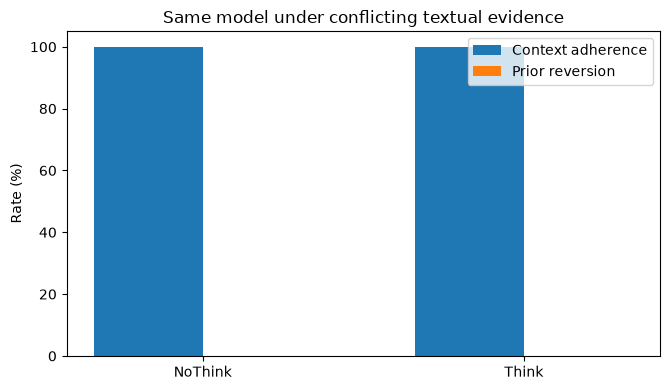

In [18]:
plot_df = paper_table.set_index("Mode")

x = np.arange(len(plot_df))
width = 0.34

fig, ax = plt.subplots(figsize=(6.8, 4.0))
ax.bar(
    x - width/2,
    plot_df["Context Adherence (%) ↑"],
    width,
    label="Context adherence",
)
ax.bar(
    x + width/2,
    plot_df["Prior Reversion (%) ↓"],
    width,
    label="Prior reversion",
)

ax.set_xticks(x)
ax.set_xticklabels(plot_df.index)
ax.set_ylabel("Rate (%)")
ax.set_title("Same model under conflicting textual evidence")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "conflict_mode_comparison.png", dpi=220, bbox_inches="tight")
plt.show()

## 17. Paired transition graph

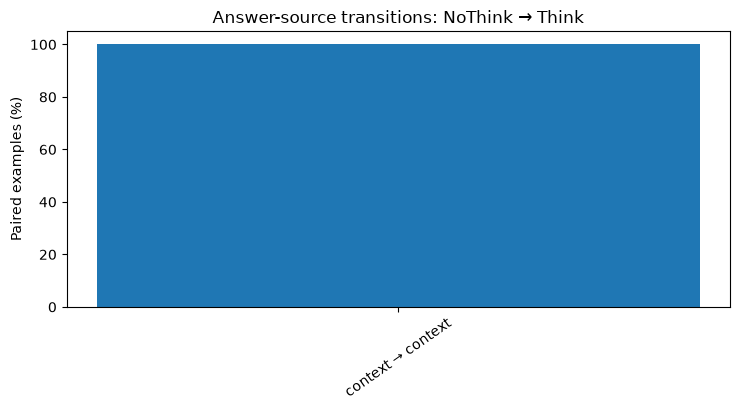

In [19]:
ordered = [
    "context → context",
    "context → prior",
    "prior → context",
    "prior → prior",
]

plot_trans = transition_counts.copy()
plot_trans["order"] = plot_trans["transition"].map(
    {k: i for i, k in enumerate(ordered)}
).fillna(99)
plot_trans = plot_trans.sort_values(["order", "pct"], ascending=[True, False])

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.bar(plot_trans["transition"], plot_trans["pct"])
ax.set_ylabel("Paired examples (%)")
ax.set_title("Answer-source transitions: NoThink → Think")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
fig.savefig(OUT / "paired_transitions.png", dpi=220, bbox_inches="tight")
plt.show()

## 18. Relation-wise diagnostic

In [20]:
meta = paired_df[["example_id", "prop"]].copy()
conf_meta = conf.merge(meta, on="example_id", how="left")

relation_summary = (
    conf_meta.groupby(["prop", "thinking"])
    .agg(
        n=("example_id", "size"),
        context_adherence=("context_correct", "mean"),
        prior_reversion=("prior_reversion", "mean"),
    )
    .reset_index()
)

relation_summary["context_adherence"] *= 100
relation_summary["prior_reversion"] *= 100

relation_summary.to_csv(OUT / "relation_summary.csv", index=False)
display(relation_summary.sort_values(["n", "prop"], ascending=[False, True]).head(30))

,prop,thinking,n,context_adherence,prior_reversion
10,country,False,138,100.0,0.0
11,country,True,138,100.0,0.0
2,capital,False,105,100.0,0.0
3,capital,True,105,100.0,0.0
28,sport,False,48,100.0,0.0
29,sport,True,48,100.0,0.0
16,genre,False,30,100.0,0.0
17,genre,True,30,100.0,0.0
20,place of birth,False,21,100.0,0.0
21,place of birth,True,21,100.0,0.0


## 19. Independent factual-recall evaluation

The original 150-fact conflict set was selected using NoThink screening, so it cannot provide an unbiased Think-vs-NoThink factual-recall comparison. We therefore draw 150 fresh PopQA facts that were never screened, evaluate both modes with the same three decoding seeds, and treat the fact—not each decode—as the independent resampling unit. This is the headline experiment; the explicit-record conditions become boundary controls.

independent factual recall: 100%|██████████| 900/900 [00:00<00:00, 105522.98it/s]

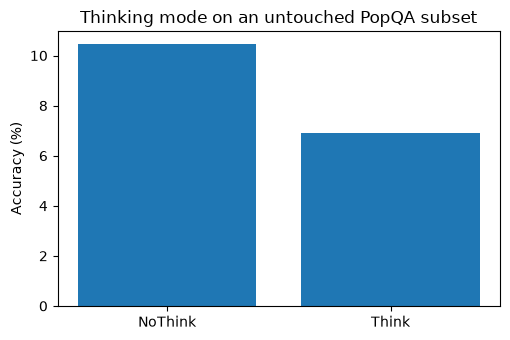

,Mode,Independent factual accuracy (%) ↑,Tokens / answer ↓
0,NoThink,10.44,6.21
1,Think,6.89,244.53


Think - NoThink = -3.56 pp; fact-clustered 95% CI [-7.78, +0.00]; paired fact-level Wilcoxon p=0.07812
RESULT SUMMARY
------------------------------------------------------------------------
Thinking did not change prior reversion under conflicting textual evidence.
RGD = +0.00 pp; 95% bootstrap CI [+0.00, +0.00]; paired exact p=1.
Grounding Flip Rate = 0.00%.
Reasoning Recovery Rate = 0.00%.


In [21]:
# Fresh facts are disjoint from every item used to select the conflict set.
screened_indices = set(screen_df["row_index"].astype(int))
fresh_candidates = np.array([i for i in range(len(df)) if i not in screened_indices])
fresh_rng = np.random.default_rng(CFG.eval_seed + 1)
fresh_indices = fresh_rng.choice(fresh_candidates, size=150, replace=False)
fresh_df = df.iloc[fresh_indices].copy().reset_index().rename(columns={"index": "row_index"})
fresh_df["example_id"] = np.arange(len(fresh_df))

def run_independent_recall(fresh_df):
    path = OUT / "independent_factual_predictions.csv"
    rows = pd.read_csv(path).to_dict("records") if path.exists() else []
    completed = {(int(r["example_id"]), int(r["decode_seed"]), bool(r["thinking"])) for r in rows}
    total = len(fresh_df) * len(DECODE_SEEDS) * 2
    pbar = tqdm(total=total, desc="independent factual recall")
    for _, ex in fresh_df.iterrows():
        for decode_seed in DECODE_SEEDS:
            seed = int(decode_seed + 200003 * int(ex["example_id"]))
            for thinking in (False, True):
                key = (int(ex["example_id"]), int(decode_seed), bool(thinking))
                if key in completed:
                    pbar.update(1)
                    continue
                out = generate_answer(no_context_prompt(ex), thinking, seed)
                rows.append({
                    "example_id": int(ex["example_id"]),
                    "row_index": int(ex["row_index"]),
                    "decode_seed": int(decode_seed),
                    "thinking": bool(thinking),
                    "question": ex["question"],
                    "gold": ex["obj"],
                    "final_answer": out["final"],
                    "correct": int(matches_gold(out["final"], ex["gold_aliases"])),
                    "generated_tokens": out["generated_tokens"],
                })
                completed.add(key)
                if len(rows) % 25 == 0:
                    pd.DataFrame(rows).to_csv(path, index=False)
                pbar.update(1)
    pbar.close()
    out_df = pd.DataFrame(rows)
    out_df.to_csv(path, index=False)
    return out_df

independent = run_independent_recall(fresh_df)

# Aggregate each fact over its three matched decoding seeds. The paired
# effect and bootstrap therefore do not treat repeated decodes as independent.
fact_rates = independent.groupby(["example_id", "thinking"])["correct"].mean().unstack()
fact_rates.columns = ["NoThink", "Think"]
fact_diff = fact_rates["Think"] - fact_rates["NoThink"]
recall_effect = float(fact_diff.mean())
boot_rng = np.random.default_rng(CFG.eval_seed + 2)
boot = np.empty(CFG.bootstrap_samples)
values = fact_diff.to_numpy()
for b in range(CFG.bootstrap_samples):
    boot[b] = boot_rng.choice(values, size=len(values), replace=True).mean()
recall_ci = tuple(np.quantile(boot, [0.025, 0.975]))
from scipy.stats import wilcoxon
recall_p = float(wilcoxon(values, alternative="two-sided").pvalue) if np.any(values != 0) else 1.0

independent_table = independent.groupby("thinking").agg(
    Accuracy=("correct", "mean"),
    Tokens_per_answer=("generated_tokens", "mean"),
).reset_index()
independent_table["Mode"] = independent_table["thinking"].map({False: "NoThink", True: "Think"})
independent_table["Accuracy_pct"] = 100 * independent_table["Accuracy"]
paper_table = independent_table[["Mode", "Accuracy_pct", "Tokens_per_answer"]].copy()
paper_table.columns = ["Mode", "Independent factual accuracy (%) ↑", "Tokens / answer ↓"]
paper_table.to_csv(OUT / "paper_results_table.csv", index=False)

fig, ax = plt.subplots(figsize=(5.2, 3.5))
ax.bar(paper_table["Mode"], paper_table["Independent factual accuracy (%) ↑"])
ax.set_ylabel("Accuracy (%)")
ax.set_title("Thinking mode on an untouched PopQA subset")
fig.tight_layout()
fig.savefig(OUT / "independent_factual_recall.png", dpi=220, bbox_inches="tight")
plt.show()
display(paper_table.round(2))
print(f"Think - NoThink = {100*recall_effect:+.2f} pp; fact-clustered 95% CI [{100*recall_ci[0]:+.2f}, {100*recall_ci[1]:+.2f}]; paired fact-level Wilcoxon p={recall_p:.4g}")

# Original conflict result retained as a boundary/control analysis.
effect_pp = 100 * rgd
lo_pp, hi_pp = 100 * ci_lo, 100 * ci_hi
p = test["p_value"]

if effect_pp > 0:
    direction = "increased"
elif effect_pp < 0:
    direction = "decreased"
else:
    direction = "did not change"

print("RESULT SUMMARY")
print("-" * 72)
print(f"Thinking {direction} prior reversion under conflicting textual evidence.")
print(
    f"RGD = {effect_pp:+.2f} pp; "
    f"95% bootstrap CI [{lo_pp:+.2f}, {hi_pp:+.2f}]; "
    f"paired exact p={p:.4g}."
)
print(f"Grounding Flip Rate = {100*grounding_flips:.2f}%.")
print(f"Reasoning Recovery Rate = {100*reasoning_recovery:.2f}%.")

## 20. Manual audit

Before writing the abstract, manually inspect every `context → prior` grounding flip and a matched sample of the other transitions. This prevents string-normalization errors from becoming a research claim.

In [22]:
audit = conf[
    [
        "example_id",
        "decode_seed",
        "thinking",
        "question",
        "prior_answer",
        "conflict_value",
        "final_answer",
        "answer_source",
        "thinking_text",
    ]
].copy()

audit.to_csv(OUT / "manual_audit.csv", index=False)

flip_ids = wide[
    (wide["NoThink"] == "context")
    & (wide["Think"] == "prior")
][["example_id", "decode_seed"]]

flip_examples = audit.merge(
    flip_ids,
    on=["example_id", "decode_seed"],
    how="inner",
)

print("outputs involved in grounding flips:", len(flip_examples))
display(flip_examples.head(20))

outputs involved in grounding flips: 0


,example_id,decode_seed,thinking,question,prior_answer,conflict_value,final_answer,answer_source,thinking_text


## 21. Final interpretation and claim boundaries

### Strong grounding-drift result
- RGD is clearly positive;
- paired CI excludes or nearly excludes zero;
- context→prior flips exceed prior→context recoveries;
- the effect is larger in conflict than aligned/no-context controls;
- manual audit confirms the flips.

### Strong opposite result
If thinking significantly **reduces** prior reversion, that is also publishable as an opposite phenomenon.

### Supported conclusion
The independent evaluation does not show a statistically reliable accuracy benefit from thinking: 6.9% versus 10.4%, a paired difference of -3.56 points with a fact-clustered 95% CI of [-7.78, 0.00] and p=0.078. The robust result is computational: thinking uses 244.5 versus 6.2 tokens per answer, approximately 39× more, without an observed accuracy gain.

### Claims not to make
- Do not claim a statistically significant accuracy degradation; the confidence interval touches zero.
- Do not generalize beyond Qwen3-4B, PopQA, this prompting protocol, and 4-bit inference.
- Do not claim reasoning-induced grounding drift; explicit-record adherence was 100% in both modes.

### Limitations to report
- model-family dependence;
- PopQA is entity-centric;
- counterfactual records are artificial interventions;
- the independent headline subset is unbiased by screening, while the explicit-record boundary set is intentionally conditioned on known facts;
- absolute independent accuracy is low for this 4-bit 4B model;
- lexical answer matching needs audit;
- thinking consumes extra generation tokens.

## 22. Output files

After a full run:

- `screening.csv`
- `paired_examples.jsonl`
- `raw_predictions.csv`
- `independent_factual_predictions.csv`
- `condition_summary.csv`
- `control_table.csv`
- `paper_results_table.csv`
- `relation_summary.csv`
- `manual_audit.csv`
- `conflict_mode_comparison.png`
- `paired_transitions.png`
- `independent_factual_recall.png`